# Graph Analytics

Devon Farber | Boston University MET CS688 coursework

Builds an undirected social network, selects a reproducible connected subgraph, compares Dijkstra and A*, compares Prim and Kruskal minimum spanning trees, and visualizes PageRank and HITS.

## Results and reproducibility
Recorded output: a connected 100-node subgraph with 558 edges, drawn from an input table of 29,790 rows. Requires person_knows_person.csv with pipe-separated source and target columns, which is not included. Unit edge weights limit shortest-path and spanning-tree comparisons; mutual edges also limit distinct hub/authority interpretation.

Saved outputs are retained from the submitted notebook. This portfolio packaging did not rerun the analysis.

See the repository README for setup and input requirements.


In [1]:
from google.colab import files

uploaded = files.upload()

Saving person_knows_person.csv to person_knows_person.csv


In [2]:
import pandas as pd

df = pd.read_csv("person_knows_person.csv", sep="|")
df.columns = ["source", "target"]

print("Dataset shape:", df.shape)
print("\nMissing values:")
print(df.isna().sum())

display(df.head())

Dataset shape: (29790, 2)

Missing values:
source    0
target    0
dtype: int64


,source,target
0,38,956
1,38,962
2,38,941
3,38,74
4,38,36


In [3]:
import networkx as nx
import matplotlib.pyplot as plt

# Treat "knows" connections as mutual, undirected relationships.
G_full = nx.from_pandas_edgelist(
    df,
    source="source",
    target="target",
    create_using=nx.Graph()
)

# Remove connections from a person to themselves.
self_loops = list(nx.selfloop_edges(G_full))
G_full.remove_edges_from(self_loops)

# The dataset has no edge weights, so each connection costs 1.
nx.set_edge_attributes(G_full, 1, "weight")

print("Full graph nodes:", G_full.number_of_nodes())
print("Full graph edges:", G_full.number_of_edges())
print("Self-loops removed:", len(self_loops))
print("Connected components:", nx.number_connected_components(G_full))
print("Is the graph connected?", nx.is_connected(G_full))

Full graph nodes: 998
Full graph edges: 14895
Self-loops removed: 0
Connected components: 1
Is the graph connected? True


In [4]:
from itertools import islice

# Start at the smallest node ID for reproducible selection.
start_node = min(G_full.nodes())

# Breadth-first traversal keeps the selected nodes connected.
bfs_nodes = nx.bfs_tree(
    G_full,
    source=start_node,
    sort_neighbors=sorted
).nodes()

selected_nodes = list(islice(bfs_nodes, 100))

# Keep all original connections among the selected nodes.
G = G_full.subgraph(selected_nodes).copy()

print("Starting node:", start_node)
print("Subgraph nodes:", G.number_of_nodes())
print("Subgraph edges:", G.number_of_edges())
print("Is the subgraph connected?", nx.is_connected(G))

assert G.number_of_nodes() == 100
assert nx.is_connected(G)

Starting node: 0
Subgraph nodes: 100
Subgraph edges: 558
Is the subgraph connected? True


In [5]:
# Use the starting node as the source.
source = start_node

# Choose the farthest reachable node, breaking ties by node ID.
distances = nx.single_source_shortest_path_length(G, source)
target = min(
    node for node, distance in distances.items()
    if distance == max(distances.values())
)

# Dijkstra shortest path.
dijkstra_path = nx.dijkstra_path(
    G, source, target, weight="weight"
)

# With unit edge costs, any different node is at least 1 hop away.
def heuristic(node, goal):
    return 0 if node == goal else 1

# A* shortest path.
astar_path = nx.astar_path(
    G, source, target,
    heuristic=heuristic,
    weight="weight"
)

dijkstra_cost = nx.path_weight(G, dijkstra_path, "weight")
astar_cost = nx.path_weight(G, astar_path, "weight")

print("Source node:", source)
print("Target node:", target)
print("\nDijkstra path:", dijkstra_path)
print("Dijkstra total cost:", dijkstra_cost)
print("\nA* path:", astar_path)
print("A* total cost:", astar_cost)
print("\nBoth costs match:", dijkstra_cost == astar_cost)

assert dijkstra_cost == astar_cost == distances[target]

Source node: 0
Target node: 91

Dijkstra path: [0, 262, 91]
Dijkstra total cost: 2

A* path: [0, 262, 91]
A* total cost: 2

Both costs match: True


In [6]:
# Each result retains only the minimum spanning tree edges.
mst_prim = nx.minimum_spanning_tree(
    G, algorithm="prim", weight="weight"
)

mst_kruskal = nx.minimum_spanning_tree(
    G, algorithm="kruskal", weight="weight"
)

prim_cost = mst_prim.size(weight="weight")
kruskal_cost = mst_kruskal.size(weight="weight")

mst_results = pd.DataFrame({
    "Algorithm": ["Prim", "Kruskal"],
    "Nodes": [
        mst_prim.number_of_nodes(),
        mst_kruskal.number_of_nodes()
    ],
    "Edges retained": [
        mst_prim.number_of_edges(),
        mst_kruskal.number_of_edges()
    ],
    "Edges removed": [
        G.number_of_edges() - mst_prim.number_of_edges(),
        G.number_of_edges() - mst_kruskal.number_of_edges()
    ],
    "Total weight": [prim_cost, kruskal_cost],
    "Is a tree": [
        nx.is_tree(mst_prim),
        nx.is_tree(mst_kruskal)
    ]
})

display(mst_results)

assert nx.is_tree(mst_prim)
assert nx.is_tree(mst_kruskal)
assert set(mst_prim.nodes()) == set(G.nodes())
assert set(mst_kruskal.nodes()) == set(G.nodes())
assert prim_cost == kruskal_cost == G.number_of_nodes() - 1

,Algorithm,Nodes,Edges retained,Edges removed,Total weight,Is a tree
0,Prim,100,99,459,99.0,True
1,Kruskal,100,99,459,99.0,True


In [7]:
# PageRank with a damping factor of 0.85.
pagerank = nx.pagerank(
    G, alpha=0.85, max_iter=1000, tol=1e-10,
    weight="weight"
)

# Represent each mutual connection as two directed edges for HITS.
G_directed = G.to_directed()

hubs, authorities = nx.hits(
    G_directed,
    max_iter=1000,
    tol=1e-10,
    nstart={node: 1.0 for node in G_directed},
    normalized=True
)

# Combine scores into a table.
rankings = pd.DataFrame({
    "Node": list(G.nodes()),
    "Degree": [G.degree(node) for node in G.nodes()],
    "PageRank": [pagerank[node] for node in G.nodes()],
    "HITS Hub": [hubs[node] for node in G.nodes()],
    "HITS Authority": [authorities[node] for node in G.nodes()]
})

for score in ["PageRank", "HITS Hub", "HITS Authority"]:
    print(f"\nTop 10 nodes by {score}:")
    display(
        rankings.sort_values(
            [score, "Node"],
            ascending=[False, True]
        ).head(10).reset_index(drop=True)
    )


Top 10 nodes by PageRank:


,Node,Degree,PageRank,HITS Hub,HITS Authority
0,0,87,0.077942,0.050862,0.050862
1,530,26,0.021402,0.020957,0.020957
2,812,26,0.020789,0.022397,0.022397
3,21,21,0.018561,0.015195,0.015195
4,451,21,0.017425,0.017116,0.017116
5,407,21,0.017223,0.017722,0.017722
6,402,21,0.016953,0.019198,0.019198
7,811,20,0.016800,0.016132,0.016132
8,492,20,0.016741,0.015949,0.015949
9,240,20,0.016449,0.017499,0.017499



Top 10 nodes by HITS Hub:


,Node,Degree,PageRank,HITS Hub,HITS Authority
0,0,87,0.077942,0.050862,0.050862
1,812,26,0.020789,0.022397,0.022397
2,530,26,0.021402,0.020957,0.020957
3,402,21,0.016953,0.019198,0.019198
4,405,20,0.016076,0.018694,0.018694
5,407,21,0.017223,0.017722,0.017722
6,240,20,0.016449,0.017499,0.017499
7,451,21,0.017425,0.017116,0.017116
8,524,19,0.015603,0.016446,0.016446
9,811,20,0.016800,0.016132,0.016132



Top 10 nodes by HITS Authority:


,Node,Degree,PageRank,HITS Hub,HITS Authority
0,0,87,0.077942,0.050862,0.050862
1,812,26,0.020789,0.022397,0.022397
2,530,26,0.021402,0.020957,0.020957
3,402,21,0.016953,0.019198,0.019198
4,405,20,0.016076,0.018694,0.018694
5,407,21,0.017223,0.017722,0.017722
6,240,20,0.016449,0.017499,0.017499
7,451,21,0.017425,0.017116,0.017116
8,524,19,0.015603,0.016446,0.016446
9,811,20,0.016800,0.016132,0.016132


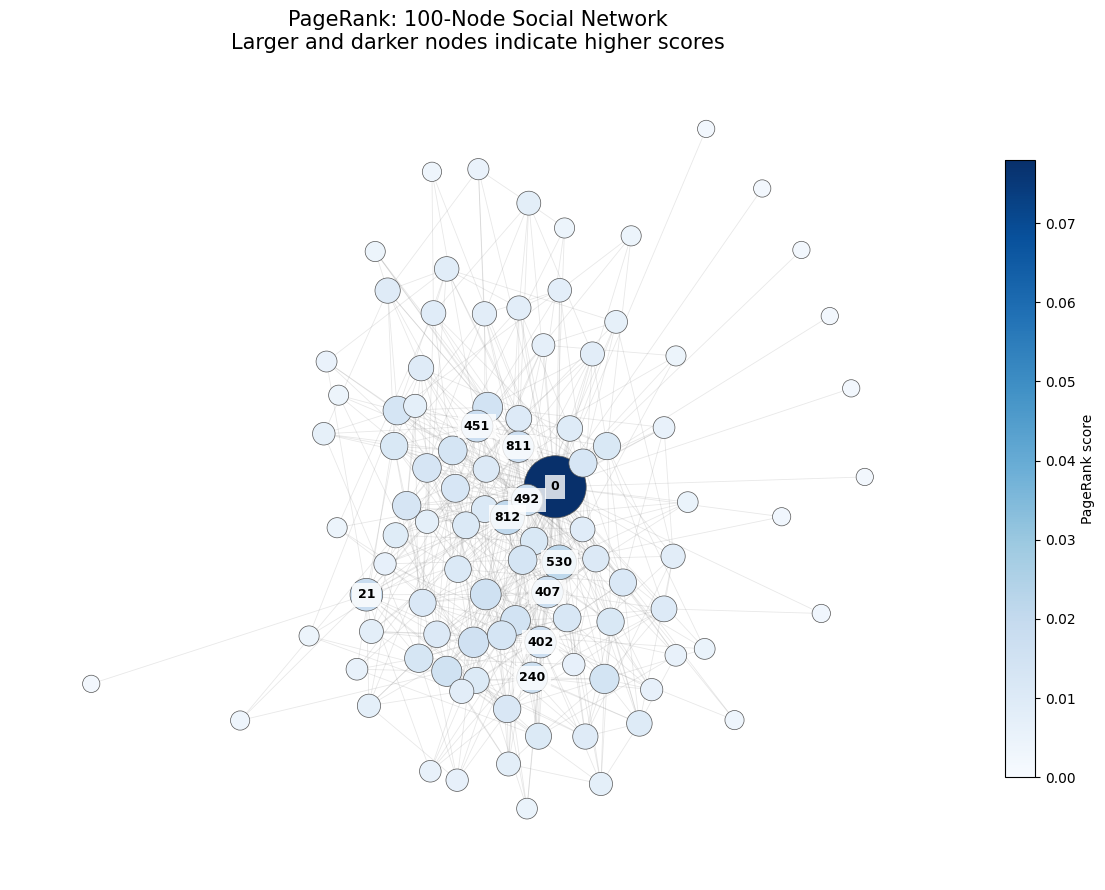

In [8]:
# Reuse this layout for all ranking plots.
pos = nx.spring_layout(G, seed=42, iterations=200)

node_order = list(G.nodes())
pr_values = [pagerank[node] for node in node_order]
pr_sizes = [
    100 + 1900 * pagerank[node] / max(pr_values)
    for node in node_order
]

top_pr_nodes = sorted(
    pagerank,
    key=lambda node: (-pagerank[node], node)
)[:10]

fig, ax = plt.subplots(figsize=(12, 9))

nx.draw_networkx_edges(
    G, pos, ax=ax,
    edge_color="gray", alpha=0.18, width=0.6
)

nodes = nx.draw_networkx_nodes(
    G, pos, ax=ax,
    nodelist=node_order,
    node_color=pr_values,
    node_size=pr_sizes,
    cmap=plt.cm.Blues,
    vmin=0,
    vmax=max(pr_values),
    edgecolors="#555555",
    linewidths=0.5
)

nx.draw_networkx_labels(
    G, pos, ax=ax,
    labels={node: str(node) for node in top_pr_nodes},
    font_size=9,
    font_weight="bold",
    bbox=dict(facecolor="white", alpha=0.8, edgecolor="none")
)

fig.colorbar(nodes, ax=ax, shrink=0.75, label="PageRank score")
ax.set_title(
    "PageRank: 100-Node Social Network\n"
    "Larger and darker nodes indicate higher scores",
    fontsize=15
)
ax.axis("off")

plt.tight_layout()
plt.savefig("pagerank_network.png", dpi=300, bbox_inches="tight")
plt.show()

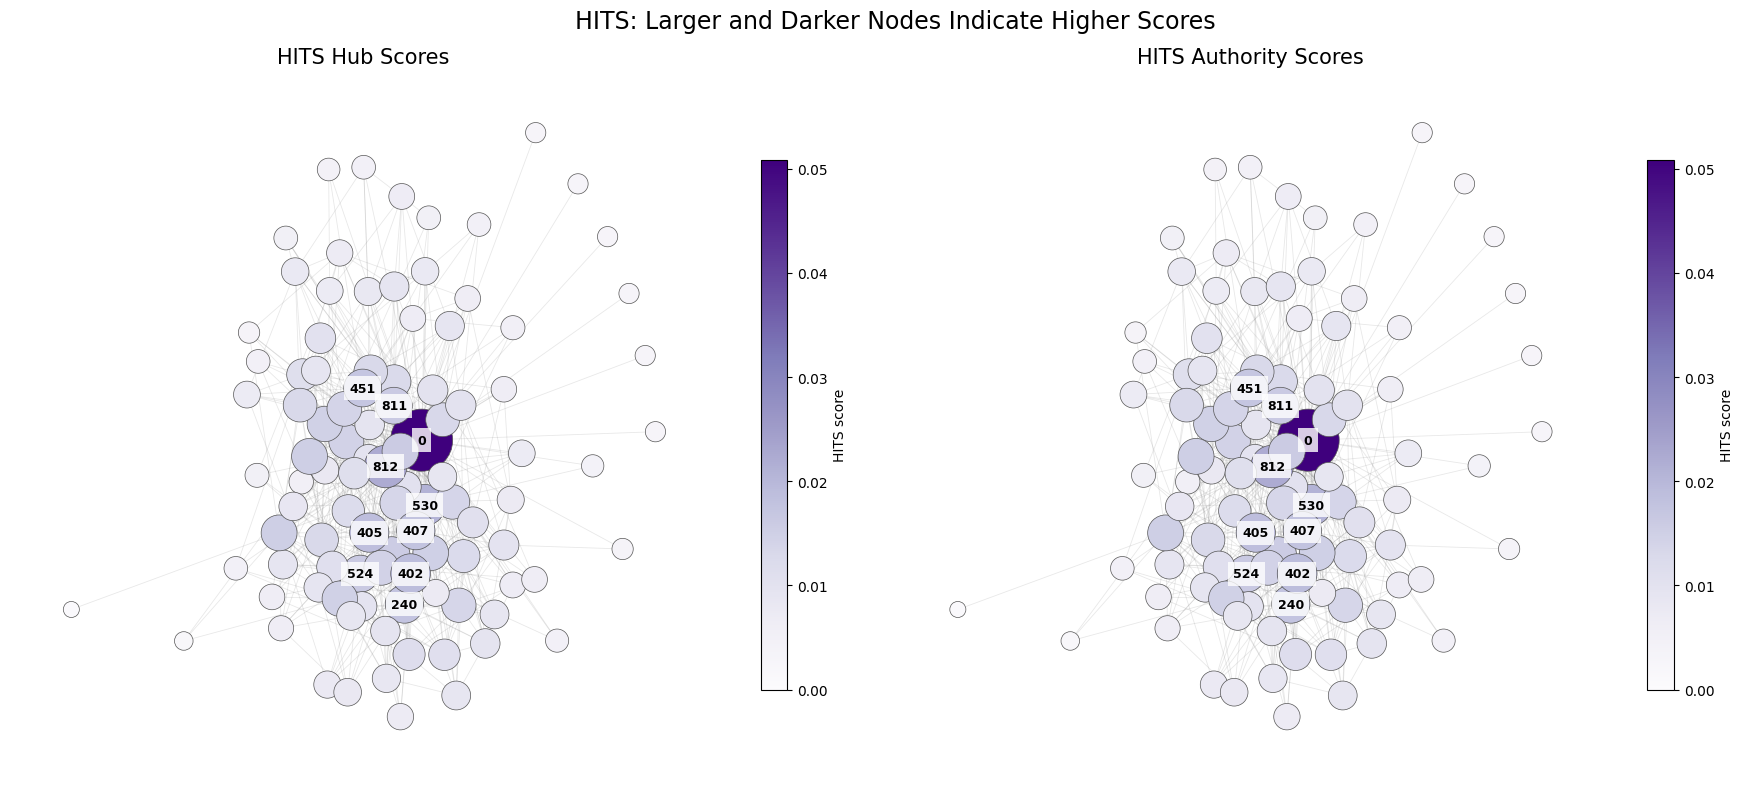

In [9]:
fig, axes = plt.subplots(figsize=(18, 8), ncols=2)

# Use one shared color scale for both HITS plots.
hits_max = max(max(hubs.values()), max(authorities.values()))

for ax, scores, title in [
    (axes[0], hubs, "HITS Hub Scores"),
    (axes[1], authorities, "HITS Authority Scores")
]:
    values = [scores[node] for node in node_order]
    sizes = [
        100 + 1900 * scores[node] / hits_max
        for node in node_order
    ]

    top_nodes = sorted(
        scores,
        key=lambda node: (-scores[node], node)
    )[:10]

    nx.draw_networkx_edges(
        G, pos, ax=ax,
        edge_color="gray", alpha=0.18, width=0.6
    )

    nodes = nx.draw_networkx_nodes(
        G, pos, ax=ax,
        nodelist=node_order,
        node_color=values,
        node_size=sizes,
        cmap=plt.cm.Purples,
        vmin=0,
        vmax=hits_max,
        edgecolors="#555555",
        linewidths=0.5
    )

    nx.draw_networkx_labels(
        G, pos, ax=ax,
        labels={node: str(node) for node in top_nodes},
        font_size=9,
        font_weight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none"
        )
    )

    fig.colorbar(nodes, ax=ax, shrink=0.75, label="HITS score")
    ax.set_title(title, fontsize=15)
    ax.axis("off")

fig.suptitle(
    "HITS: Larger and Darker Nodes Indicate Higher Scores",
    fontsize=17
)

plt.tight_layout()
plt.savefig("hits_network.png", dpi=300, bbox_inches="tight")
plt.show()

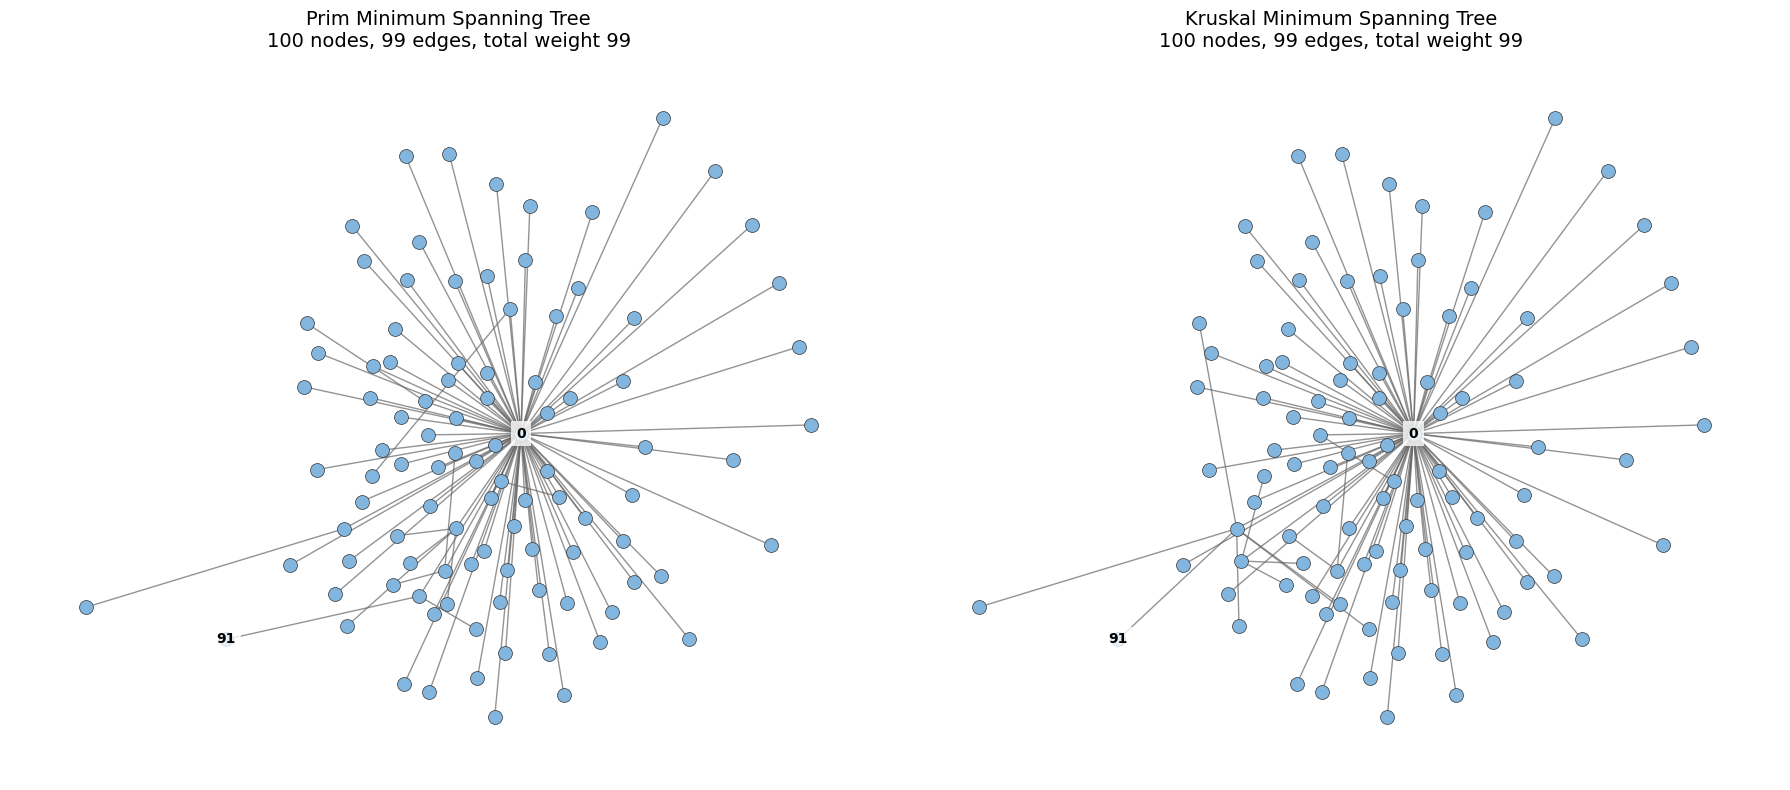

In [10]:
fig, axes = plt.subplots(ncols=2, figsize=(18, 8))

for ax, tree, title in [
    (axes[0], mst_prim, "Prim Minimum Spanning Tree"),
    (axes[1], mst_kruskal, "Kruskal Minimum Spanning Tree")
]:
    nx.draw_networkx_edges(
        tree, pos, ax=ax,
        edge_color="#666666",
        width=1.0,
        alpha=0.7
    )

    nx.draw_networkx_nodes(
        tree, pos, ax=ax,
        node_size=100,
        node_color="#82b6df",
        edgecolors="#333333",
        linewidths=0.5
    )

    nx.draw_networkx_labels(
        tree, pos, ax=ax,
        labels={source: str(source), target: str(target)},
        font_size=10,
        font_weight="bold",
        bbox=dict(
            facecolor="white",
            alpha=0.8,
            edgecolor="none"
        )
    )

    ax.set_title(
        f"{title}\n"
        f"{tree.number_of_nodes()} nodes, "
        f"{tree.number_of_edges()} edges, "
        f"total weight {tree.size(weight='weight'):.0f}",
        fontsize=14
    )
    ax.axis("off")

plt.tight_layout()
plt.savefig("mst_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

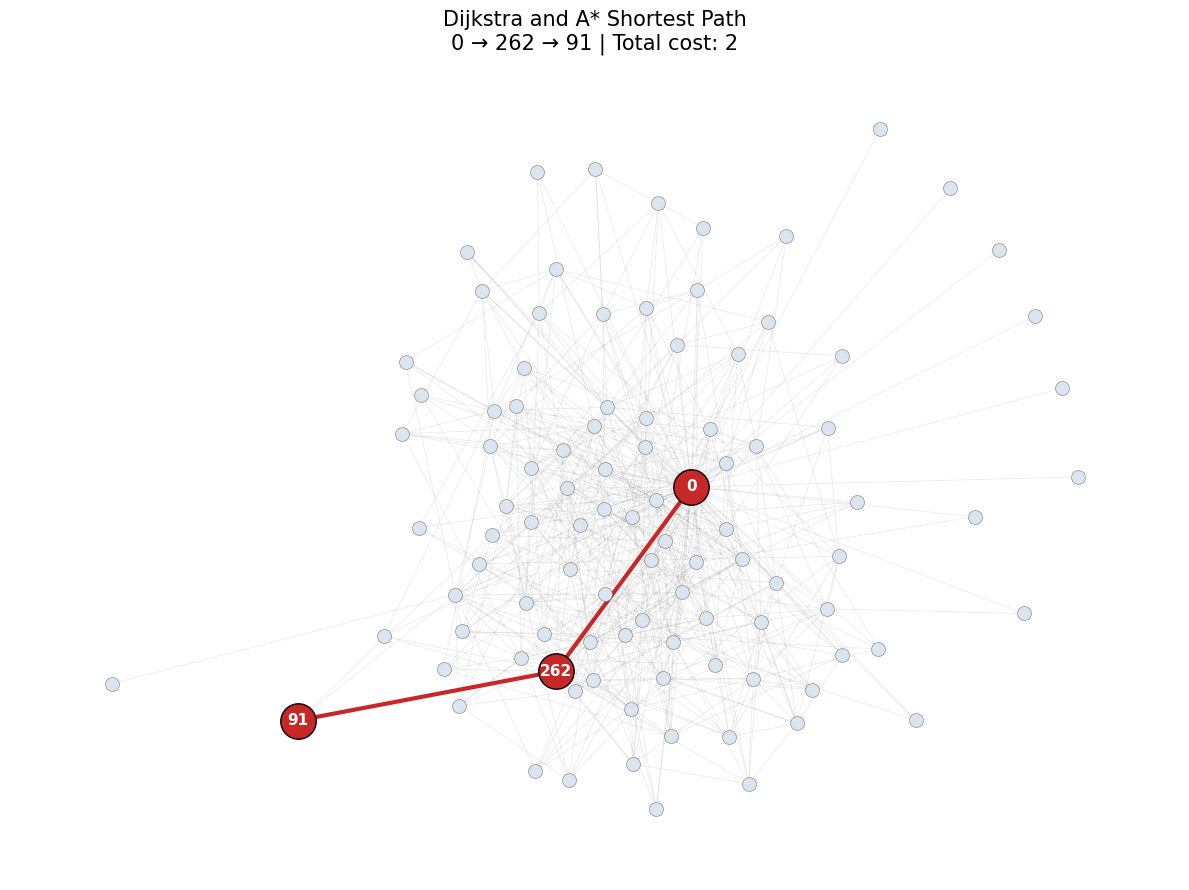

In [11]:
fig, ax = plt.subplots(figsize=(12, 9))

# Draw the original subgraph in the background.
nx.draw_networkx_edges(
    G, pos, ax=ax,
    edge_color="gray", alpha=0.15, width=0.6
)

nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_size=100,
    node_color="#dbe5ef",
    edgecolors="#777777",
    linewidths=0.4
)

# Highlight the shortest path.
path_edges = list(zip(dijkstra_path[:-1], dijkstra_path[1:]))

nx.draw_networkx_edges(
    G, pos, ax=ax,
    edgelist=path_edges,
    edge_color="#c62828",
    width=3
)

nx.draw_networkx_nodes(
    G, pos, ax=ax,
    nodelist=dijkstra_path,
    node_size=650,
    node_color="#c62828",
    edgecolors="black"
)

nx.draw_networkx_labels(
    G, pos, ax=ax,
    labels={node: str(node) for node in dijkstra_path},
    font_color="white",
    font_size=11,
    font_weight="bold"
)

route_text = " → ".join(map(str, dijkstra_path))
ax.set_title(
    f"Dijkstra and A* Shortest Path\n"
    f"{route_text} | Total cost: {dijkstra_cost}",
    fontsize=15
)
ax.axis("off")

plt.tight_layout()
plt.savefig("shortest_path.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
import zipfile
from pathlib import Path

# Save rankings and algorithm results.
rankings.sort_values(
    ["PageRank", "Node"], ascending=[False, True]
).to_csv("node_rankings.csv", index=False)

mst_results.to_csv("mst_results.csv", index=False)

pd.DataFrame({
    "Algorithm": ["Dijkstra", "A*"],
    "Source": [source, source],
    "Target": [target, target],
    "Path": [str(dijkstra_path), str(astar_path)],
    "Total cost": [dijkstra_cost, astar_cost]
}).to_csv("shortest_path_results.csv", index=False)

# Save the selected graph and both trees.
for graph, filename in [
    (G, "subgraph_edges.csv"),
    (mst_prim, "prim_mst_edges.csv"),
    (mst_kruskal, "kruskal_mst_edges.csv")
]:
    nx.to_pandas_edgelist(graph).to_csv(filename, index=False)

export_files = [
    "node_rankings.csv",
    "mst_results.csv",
    "shortest_path_results.csv",
    "subgraph_edges.csv",
    "prim_mst_edges.csv",
    "kruskal_mst_edges.csv",
    "pagerank_network.png",
    "hits_network.png",
    "mst_comparison.png",
    "shortest_path.png"
]

# Check that every file exists before packaging.
for filename in export_files:
    assert Path(filename).is_file(), f"Missing file: {filename}"

zip_name = "CS688_Homework4_Results.zip"

with zipfile.ZipFile(
    zip_name, "w", compression=zipfile.ZIP_DEFLATED
) as archive:
    for filename in export_files:
        archive.write(filename)

print(f"Packaged {len(export_files)} files.")
files.download(zip_name)

Packaged 10 files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>